In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import zscore
from statsmodels.tsa.stattools import adfuller
from statsmodels.tsa.statespace.sarimax import SARIMAX
from sklearn.metrics import mean_absolute_error, mean_squared_error
from prophet import Prophet
from prophet.diagnostics import cross_validation, performance_metrics
from statsmodels.graphics.tsaplots import plot_pacf
import pickle

In [71]:
# Load the dataset
df = pd.read_csv(
    "daily-minimum-temperatures-in-me.csv",
    skipfooter=2,
    engine="python"
)

Data collection and Initial Collection

In [72]:
df.head()

,Date,"Daily minimum temperatures in Melbourne, Australia, 1981-1990"
0,1981-01-01,20.7
1,1981-01-02,17.9
2,1981-01-03,18.8
3,1981-01-04,14.6
4,1981-01-05,15.8


In [73]:
df.rename(columns={
    "Daily minimum temperatures in Melbourne, Australia, 1981-1990": "Temperature"
}, inplace=True)

In [74]:
df.tail()

,Date,Temperature
3645,1990-12-27,14.0
3646,1990-12-28,13.6
3647,1990-12-29,13.5
3648,1990-12-30,15.7
3649,1990-12-31,13.0


In [75]:
df.shape

(3650, 2)

In [76]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 3650 entries, 0 to 3649
Data columns (total 2 columns):
 #   Column       Non-Null Count  Dtype
---  ------       --------------  -----
 0   Date         3650 non-null   str  
 1   Temperature  3650 non-null   str  
dtypes: str(2)
memory usage: 105.7 KB


In [77]:
df.describe()

,Date,Temperature
count,3650,3650
unique,3650,230
top,1981-01-01,11.0
freq,1,51


In [78]:
df.isnull().sum()

Date           0
Temperature    0
dtype: int64

In [79]:
df.duplicated().sum()

np.int64(0)

 Data Cleaning and Transformation

In [80]:
df["Date"]= pd.to_datetime(df["Date"])

In [81]:
df.dtypes

Date           datetime64[us]
Temperature               str
dtype: object

In [82]:
df.loc[[565, 566, 1290], ["Date", "Temperature"]]

,Date,Temperature
565,1982-07-20,?0.2
566,1982-07-21,?0.8
1290,1984-07-14,?0.1


In [83]:
df["Temperature"]=pd.to_numeric(df["Temperature"],errors="coerce")

In [84]:
df[df["Temperature"].isnull()]

,Date,Temperature
565,1982-07-20,NaN
566,1982-07-21,NaN
1290,1984-07-14,NaN


In [85]:
df.isnull().sum()

Date           0
Temperature    3
dtype: int64

In [86]:
raw_df = df.copy()

In [87]:
df.iloc[562:569]


,Date,Temperature
562,1982-07-17,3.7
563,1982-07-18,3.9
564,1982-07-19,5.2
565,1982-07-20,NaN
566,1982-07-21,NaN
567,1982-07-22,0.9
568,1982-07-23,3.5


In [88]:
df.iloc[1287:1294]

,Date,Temperature
1287,1984-07-11,8.8
1288,1984-07-12,8.0
1289,1984-07-13,0.7
1290,1984-07-14,NaN
1291,1984-07-15,0.9
1292,1984-07-16,7.8
1293,1984-07-17,7.2


In [89]:
df["Temperature"] = (
    raw_df["Temperature"]
    .astype(str)
    .str.replace("?", "", regex=False)
)

df["Temperature"] = pd.to_numeric(
    df["Temperature"],
    
)

In [90]:
df.isnull().sum()
df.dtypes

Date           datetime64[us]
Temperature           float64
dtype: object

In [91]:
print("Start date:", df["Date"].min())
print("End date:", df["Date"].max())

Start date: 1981-01-01 00:00:00
End date: 1990-12-31 00:00:00


In [92]:
print("Total rows:", len(df))
print("Unique dates:", df["Date"].nunique())

Total rows: 3650
Unique dates: 3650


In [93]:
date_difference = df["Date"].sort_values().diff()

print(date_difference.value_counts())

Date
1 days    3647
2 days       2
Name: count, dtype: int64


In [94]:
# Create a complete daily date range
full_dates = pd.date_range(
    start=df["Date"].min(),
    end=df["Date"].max(),
    freq="D"
)

missing_dates = full_dates.difference(df["Date"])

print("Missing dates:", len(missing_dates))
print(missing_dates)

Missing dates: 2
DatetimeIndex(['1984-12-31', '1988-12-31'], dtype='datetime64[us]', freq=None)


In [95]:
# Check records around the missing date
df[
    (df["Date"] >="1984-12-29") &
    (df["Date"] <= "1985-01-02")
]

,Date,Temperature
1458,1984-12-29,16.0
1459,1984-12-30,16.4
1460,1985-01-01,13.3
1461,1985-01-02,15.2


In [96]:
df[
    (df["Date"] >= "1988-12-29") &
    (df["Date"] <= "1989-01-02")
]

,Date,Temperature
2918,1988-12-29,14.8
2919,1988-12-30,14.1
2920,1989-01-01,14.3
2921,1989-01-02,17.4


In [97]:
df=df.set_index("Date")
df=df.asfreq("D")

In [98]:
print("Total rows:", len(df))
print("Missing temperature:", df["Temperature"].isnull().sum())
print("Date frequency:", df.index.freq)

Total rows: 3652
Missing temperature: 5
Date frequency: <Day>


In [99]:
df[df["Temperature"].isna()]

,Temperature
Date,
1982-07-20,NaN
1982-07-21,NaN
1984-07-14,NaN
1984-12-31,NaN
1988-12-31,NaN


In [100]:
df["Temperature"].interpolate(method="time")

Date
1981-01-01    20.7
1981-01-02    17.9
1981-01-03    18.8
1981-01-04    14.6
1981-01-05    15.8
              ... 
1990-12-27    14.0
1990-12-28    13.6
1990-12-29    13.5
1990-12-30    15.7
1990-12-31    13.0
Freq: D, Name: Temperature, Length: 3652, dtype: float64

In [101]:
interpolated = df["Temperature"].interpolate(method="time")

In [102]:
print("Missing before:", df["Temperature"].isna().sum())

Missing before: 5


In [103]:
print("Missing after:", interpolated.isna().sum())

Missing after: 0


In [104]:
df["Temperature"]= interpolated

In [105]:
df.isnull().sum()

Temperature    0
dtype: int64

In [106]:
df.loc[
    ["1982-07-20", "1982-07-21", "1984-07-14",
     "1984-12-31", "1988-12-31"]
]

,Temperature
Date,
1982-07-20,3.766667
1982-07-21,2.333333
1984-07-14,0.800000
1984-12-31,14.850000
1988-12-31,14.200000


In [107]:
df["Temperature"].describe()

count    3652.000000
mean       11.181175
std         4.067777
min         0.000000
25%         8.300000
50%        11.000000
75%        14.000000
max        26.300000
Name: Temperature, dtype: float64

In [108]:
print("Average temperature:", df["Temperature"].mean())
print("Minimum temperature:", df["Temperature"].min())
print("Maximum temperature:", df["Temperature"].max())

Average temperature: 11.181174698795179
Minimum temperature: 0.0
Maximum temperature: 26.3


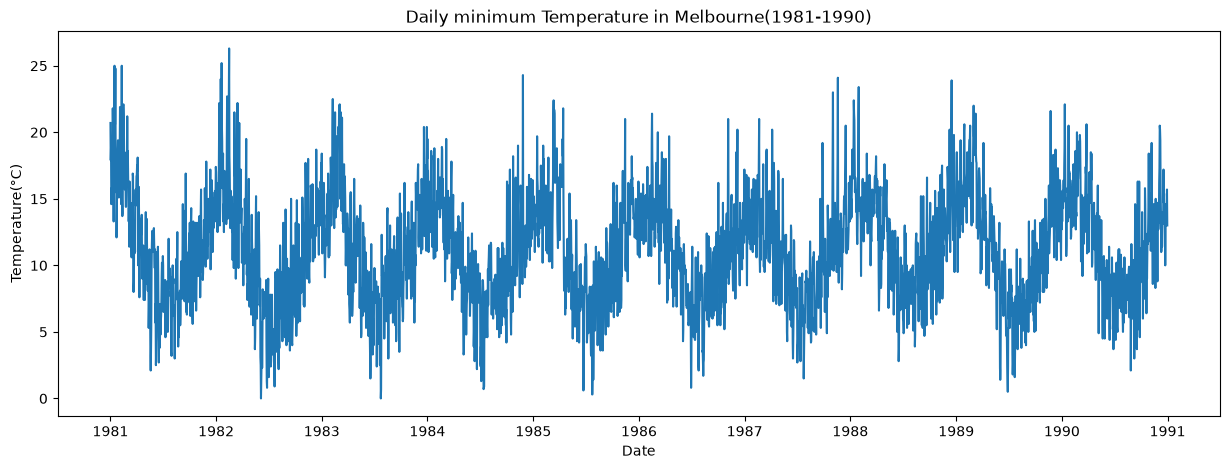

In [109]:
#Daily Temperature Trend
plt.figure(figsize=(15,5))
plt.plot(df.index,df["Temperature"])
plt.title("Daily minimum Temperature in Melbourne(1981-1990)")
plt.xlabel("Date")
plt.ylabel("Temperature(°C)")
plt.show()

In [110]:
# Outlier Detection Using Z-score
df["Z_score"]= zscore(df["Temperature"])
outliers=df[df["Z_score"].abs()>3]
print("Number of potential outliers:", len(outliers))
outliers

Number of potential outliers: 10


,Temperature,Z_score
Date,,
1981-01-15,25.0,3.397610
1981-01-18,24.8,3.348436
1981-02-09,25.0,3.397610
1982-01-17,24.0,3.151742
1982-01-20,25.2,3.446783
1982-02-15,26.3,3.717238
1984-11-26,24.3,3.225502
1987-11-19,24.1,3.176328
1988-01-30,23.4,3.004221


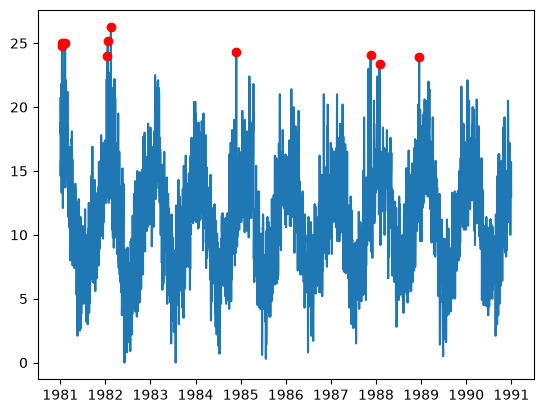

In [111]:
# Visualizing Potential Outliers
plt.Figure(figsize=(15,5))
plt.plot(df.index, df["Temperature"], label="Daily minimum temperature")

plt.scatter(
    outliers.index,
    outliers['Temperature'],
    color="red",
    label="Potential outliers",
    zorder=3
)

In [112]:
monthly_avg=df["Temperature"].resample("MS").mean()
monthly_avg.head(12)

Date
1981-01-01    17.712903
1981-02-01    17.678571
1981-03-01    13.500000
1981-04-01    12.356667
1981-05-01     9.490323
1981-06-01     7.306667
1981-07-01     7.577419
1981-08-01     7.238710
1981-09-01    10.143333
1981-10-01    10.087097
1981-11-01    11.890000
1981-12-01    13.680645
Freq: MS, Name: Temperature, dtype: float64

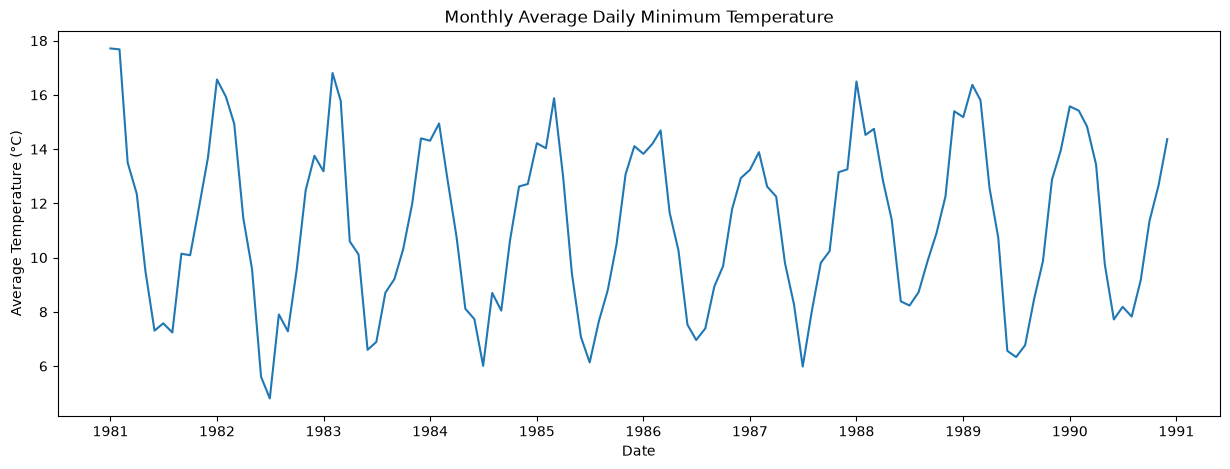

In [113]:
# Visualizing Monthly Average Temperature
plt.figure(figsize=(15, 5))
plt.plot(monthly_avg)
plt.title("Monthly Average Daily Minimum Temperature")
plt.xlabel("Date")
plt.ylabel("Average Temperature (°C)")
plt.show()

In [114]:
monthly_pattern = df.groupby(df.index.month)["Temperature"].mean()
print(monthly_pattern)

Date
1     15.030323
2     15.373759
3     14.565484
4     12.088333
5      9.866452
6      7.278333
7      6.711290
8      7.891290
9      8.976333
10    10.309355
11    12.479667
12    13.856290
Name: Temperature, dtype: float64


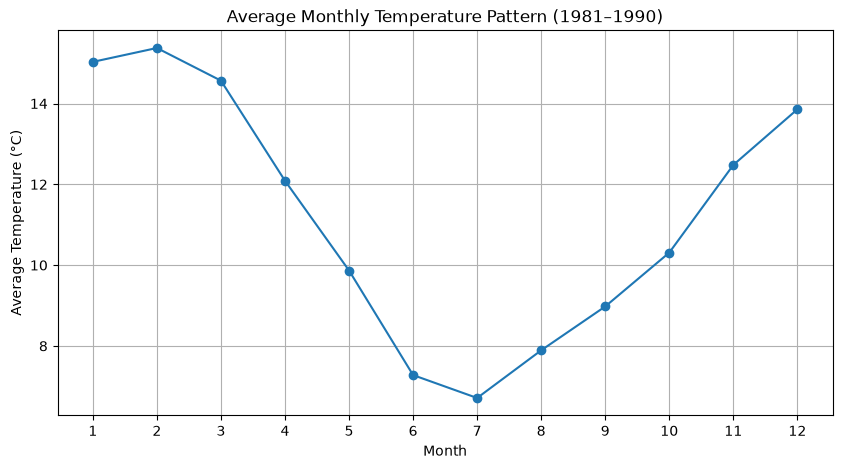

In [ ]:
# Average Monthly Temperature Pattern
plt.figure(figsize=(10, 5))
plt.plot(monthly_pattern.index, monthly_pattern.values, marker="o")

plt.title("Average Monthly Temperature Pattern (1981–1990)")
plt.xlabel("Month")
plt.ylabel("Average Temperature (°C)")
plt.xticks(range(1, 13))

plt.grid(True)
plt.show()

In [ ]:
# Stationarity Test Using ADF
result=adfuller(df["Temperature"])
print("ADF Statistics:", result[0])
print("p-value:", result[1])

ADF Statistics: -4.436765044195099
p-value: 0.00025538387462353


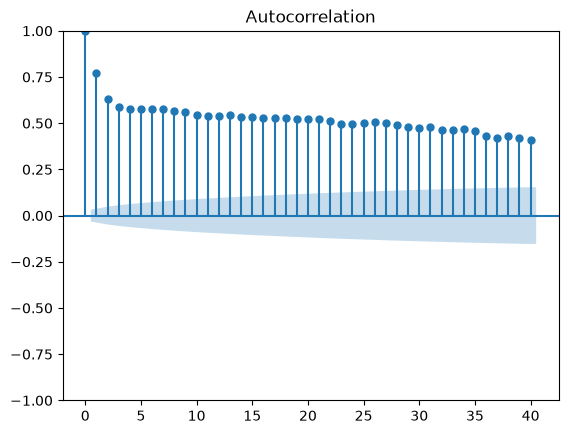

In [136]:
# Autocorrelation Analysis (ACF)
plot_acf(df["Temperature"], lags=40)
plt.show()

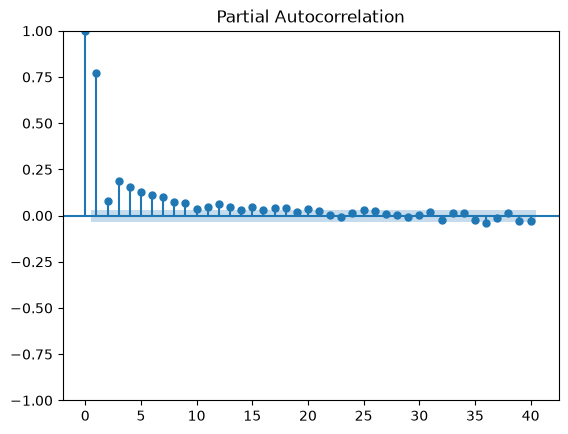

In [ ]:
# Partial Autocorrelation Analysis (PACF)
plot_pacf(df["Temperature"], lags=40, method="ywm")
plt.show()

In [ ]:
# Data Splitting
train = df.loc[:'1988-12-31', 'Temperature']
test = df.loc['1989-01-01':, 'Temperature']

print("Training data:", len(train))
print("Testing data:", len(test))

Training data: 2922
Testing data: 730


In [120]:
# Create the SARIMA model
model = SARIMAX(
    train,
    order=(1, 0, 1),          # Non-seasonal parameters
    seasonal_order=(1, 0, 1, 12),  # Seasonal parameters
    enforce_stationarity=False,
    enforce_invertibility=False
)

# Train the model using training data
model_fit = model.fit()

# Display the model summary
print(model_fit.summary())

                                     SARIMAX Results                                      
Dep. Variable:                        Temperature   No. Observations:                 2922
Model:             SARIMAX(1, 0, 1)x(1, 0, 1, 12)   Log Likelihood               -6940.594
Date:                            Thu, 29 Oct 2026   AIC                          13891.187
Time:                                    15:10:17   BIC                          13921.063
Sample:                                01-01-1981   HQIC                         13901.951
                                     - 12-31-1988                                         
Covariance Type:                              opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1          0.8590      0.012     69.866      0.000       0.835       0.883
ma.L1         -0.2475      0.022   

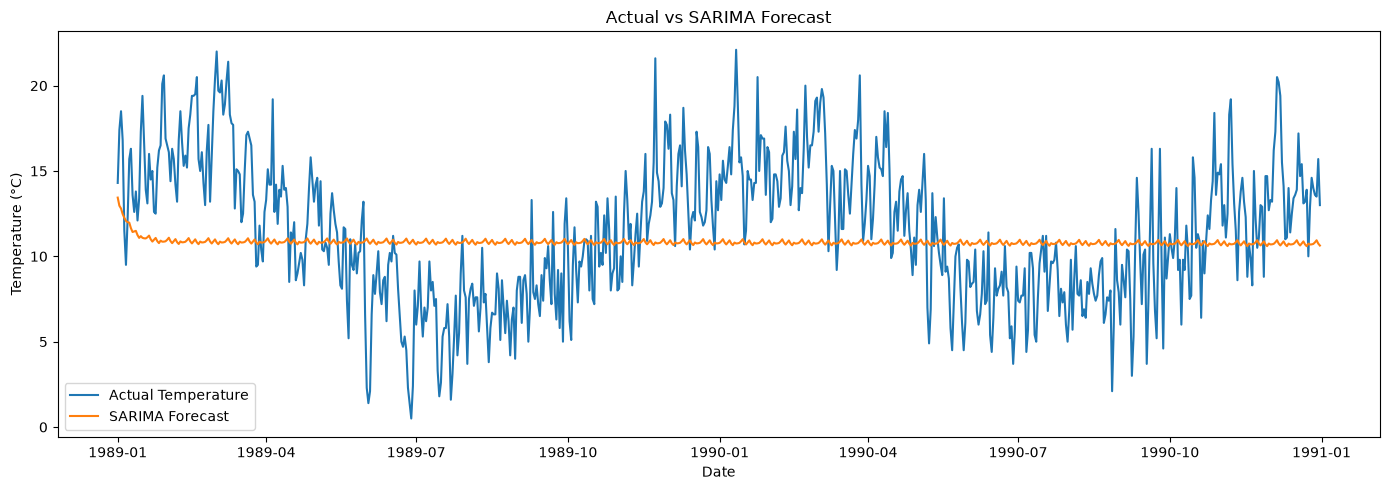

In [121]:

# Forecast temperatures for the entire testing period
forecast_sarima = model_fit.forecast(steps=len(test))

# Plot the actual temperatures
plt.figure(figsize=(14, 5))
plt.plot(test.index, test, label="Actual Temperature")

# Plot the temperatures predicted by SARIMA
plt.plot(test.index, forecast_sarima, label="SARIMA Forecast")

# Add labels and title to the graph
plt.xlabel("Date")
plt.ylabel("Temperature (°C)")
plt.title("Actual vs SARIMA Forecast")

# Display the legend and graph
plt.legend()
plt.tight_layout()
plt.show()

In [122]:

# Calculate Mean Absolute Error
mae = mean_absolute_error(test, forecast_sarima)

# Calculate Root Mean Squared Error
rmse = np.sqrt(mean_squared_error(test, forecast_sarima))

# Display the evaluation metrics
print("SARIMA MAE:", mae)
print("SARIMA RMSE:", rmse)

SARIMA MAE: 3.3900415366902976
SARIMA RMSE: 4.130672228619277


In [123]:
pip install prophet

Note: you may need to restart the kernel to use updated packages.


In [124]:
# Create the training dataframe in Prophet's required format
train_prophet = train.reset_index()

# Rename the date and temperature columns
train_prophet.columns = ["ds", "y"]

# Display the first five rows
print(train_prophet.head())

          ds     y
0 1981-01-01  20.7
1 1981-01-02  17.9
2 1981-01-03  18.8
3 1981-01-04  14.6
4 1981-01-05  15.8


In [125]:
# Create the model with yearly seasonality enabled
model_prophet = Prophet(
    yearly_seasonality=True,
    weekly_seasonality=False,
    daily_seasonality=False
)

# Train the model using the training data
model_prophet.fit(train_prophet)
print("Prophet model training completed!")

15:10:19 - cmdstanpy - INFO - Chain [1] start processing
15:10:19 - cmdstanpy - INFO - Chain [1] done processing


Prophet model training completed!


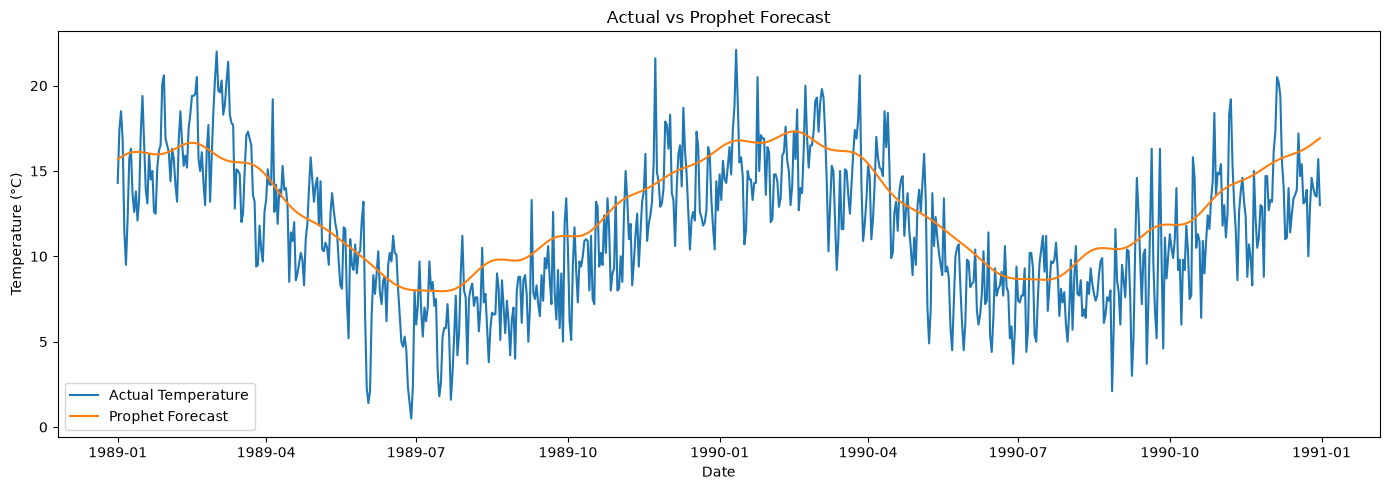

In [126]:
# Create future dates for the testing period
future = pd.DataFrame({"ds": test.index})

# Generate temperature forecasts for those dates
forecast_prophet = model_prophet.predict(future)

plt.figure(figsize=(14, 5))

# Plot the actual temperatures
plt.plot(test.index, test.values, label="Actual Temperature")

# Plot Prophet's predicted temperatures
plt.plot(
    forecast_prophet["ds"],
    forecast_prophet["yhat"],
    label="Prophet Forecast"
)

# Add the graph labels and legend
plt.xlabel("Date")
plt.ylabel("Temperature (°C)")
plt.title("Actual vs Prophet Forecast")
plt.legend()
plt.tight_layout()
plt.show()

In [127]:

# Calculate MAE using actual and predicted temperatures
mae_prophet = mean_absolute_error(test.values, forecast_prophet["yhat"])

# Calculate RMSE
rmse_prophet = np.sqrt(
    mean_squared_error(test.values, forecast_prophet["yhat"])
)

# Display the results
print("Prophet MAE:", mae_prophet)
print("Prophet RMSE:", rmse_prophet)

Prophet MAE: 2.341709048832098
Prophet RMSE: 2.8839204444344118


In [137]:

df_cv = cross_validation(
    model_prophet,
    initial="1460 days",
    period="365 days",
    horizon="365 days"
)

metrics = performance_metrics(df_cv)

print(metrics[["mae", "rmse"]].mean())

  0%|          | 0/4 [00:00<?, ?it/s]

15:13:15 - cmdstanpy - INFO - Chain [1] start processing
15:13:15 - cmdstanpy - INFO - Chain [1] done processing
15:13:15 - cmdstanpy - INFO - Chain [1] start processing
15:13:16 - cmdstanpy - INFO - Chain [1] done processing
15:13:16 - cmdstanpy - INFO - Chain [1] start processing
15:13:16 - cmdstanpy - INFO - Chain [1] done processing
15:13:16 - cmdstanpy - INFO - Chain [1] start processing
15:13:16 - cmdstanpy - INFO - Chain [1] done processing


mae     2.253663
rmse    2.819047
dtype: float64


In [129]:

# Create a Prophet model with a different trend setting
model_tuned = Prophet(
    yearly_seasonality=True,
    weekly_seasonality=False,
    daily_seasonality=False,
    changepoint_prior_scale=0.01
)

# Train the model on the training data
model_tuned.fit(train_prophet)

15:10:21 - cmdstanpy - INFO - Chain [1] start processing
15:10:21 - cmdstanpy - INFO - Chain [1] done processing


In [130]:
# Save the trained model 
with open("prophet_model.pkl", "wb") as file:
    pickle.dump(model_tuned, file) 

In [131]:
# Predict temperatures for the test period
future = pd.DataFrame({"ds": test.index})
pred = model_tuned.predict(future)["yhat"]

# Calculate evaluation errors
mae = mean_absolute_error(test, pred)
rmse = np.sqrt(mean_squared_error(test, pred))

# Display the results
print("MAE:", mae)
print("RMSE:", rmse)

MAE: 2.031140662505536
RMSE: 2.571919334403441


In [132]:
df_cv_tuned = cross_validation(
    model_tuned,
    initial="1460 days",
    period="365 days",
    horizon="365 days"
)

metrics_tuned = performance_metrics(df_cv_tuned)
print(metrics_tuned[["mae", "rmse"]].mean())

  0%|          | 0/4 [00:00<?, ?it/s]

15:10:21 - cmdstanpy - INFO - Chain [1] start processing
15:10:22 - cmdstanpy - INFO - Chain [1] done processing
15:10:22 - cmdstanpy - INFO - Chain [1] start processing
15:10:22 - cmdstanpy - INFO - Chain [1] done processing
15:10:22 - cmdstanpy - INFO - Chain [1] start processing
15:10:22 - cmdstanpy - INFO - Chain [1] done processing
15:10:22 - cmdstanpy - INFO - Chain [1] start processing
15:10:23 - cmdstanpy - INFO - Chain [1] done processing


mae     2.274813
rmse    2.849637
dtype: float64


In [133]:
# Generate predictions for the test period
future = pd.DataFrame({"ds": test.index})
forecast = model_prophet.predict(future)

# Actual and predicted temperatures together
results = pd.DataFrame({
    "Actual": test.values,
    "Predicted": forecast["yhat"].values
}, index=test.index)

print(results.head())

            Actual  Predicted
Date                         
1989-01-01    14.3  15.687165
1989-01-02    17.4  15.753970
1989-01-03    18.5  15.817029
1989-01-04    16.8  15.875540
1989-01-05    11.5  15.928785


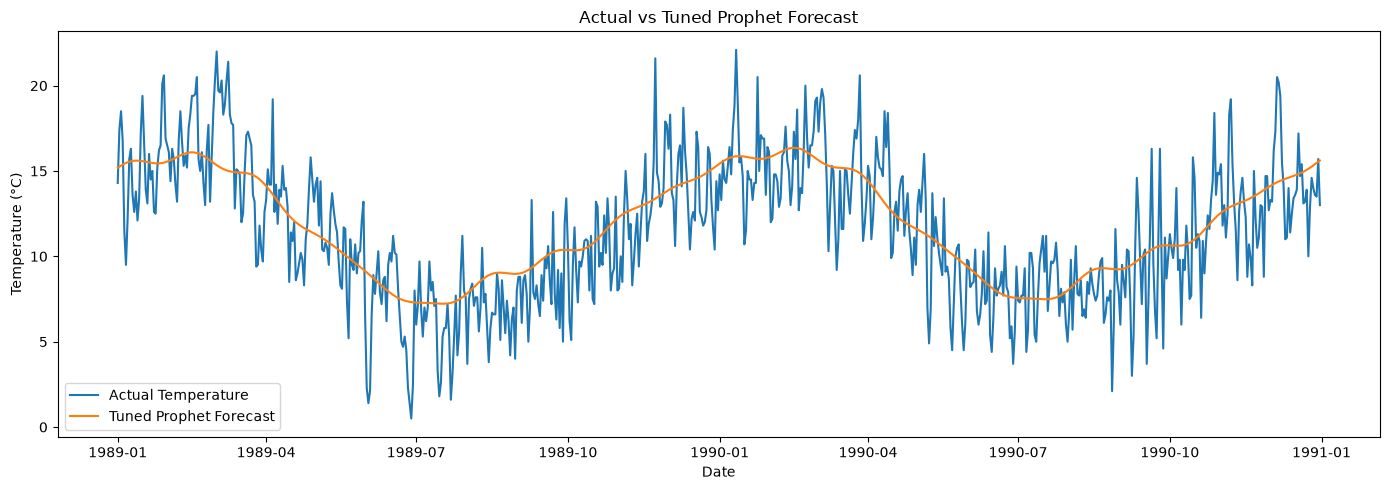

In [134]:
# Create future dates for testing
future = pd.DataFrame({"ds": test.index})

# Predict using the tuned Prophet model
forecast_prophet = model_tuned.predict(future)

# Plot actual vs tuned forecast
plt.figure(figsize=(14, 5))
plt.plot(test.index, test.values, label="Actual Temperature")
plt.plot(
    forecast_prophet["ds"],
    forecast_prophet["yhat"],
    label="Tuned Prophet Forecast"
)

plt.xlabel("Date")
plt.ylabel("Temperature (°C)")
plt.title("Actual vs Tuned Prophet Forecast")
plt.legend()
plt.tight_layout()
plt.show()